In [23]:
import sys
import os
import pandas as pd
sys.path.append(os.path.abspath('../src'))
import visualizations as vis
df_logistics = pd.read_parquet('../dataset/processed/mart_logistics_experience.parquet')
df_intent = pd.read_parquet('../dataset/processed/mart_impulse_penalty.parquet')

### 1. Returns vs. fulfilment time: binned comparison (descriptive)

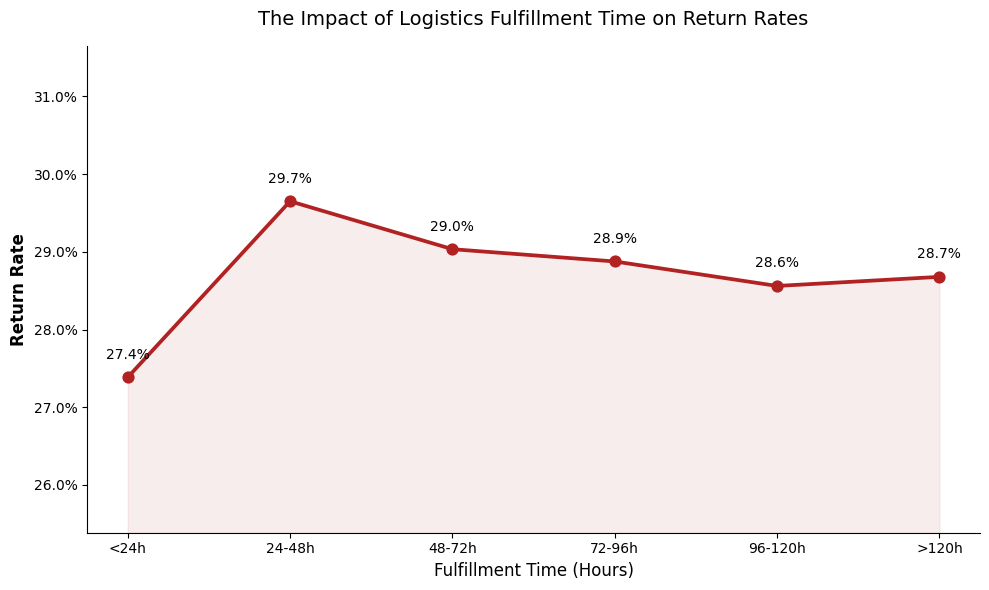

In [8]:
vis.plot_logistics_trend(df_logistics)

**Question:** Are longer fulfilment times associated with higher return rates?

**Observation:** In `mart_logistics_experience` (delivered orders), the order-level return rate stays within about 28–30% across fulfilment-time bins, from under 24 hours to over 120 hours.

**Interpretation:** In this dataset, fulfilment time is not associated with a higher return rate. This is a descriptive comparison of group means with no significance test and no adjustment for product mix, order size or customer attributes, and the data is synthetic. It gives no reason to expect that faster shipping alone would reduce returns, but it cannot rule out an effect.

**Next step:** Look at multi-warehouse split shipments (`total_dc > 1`) and add confidence intervals and bin sizes to the chart.

### 2. Returns vs. fulfilment time: fitted return probability (descriptive)

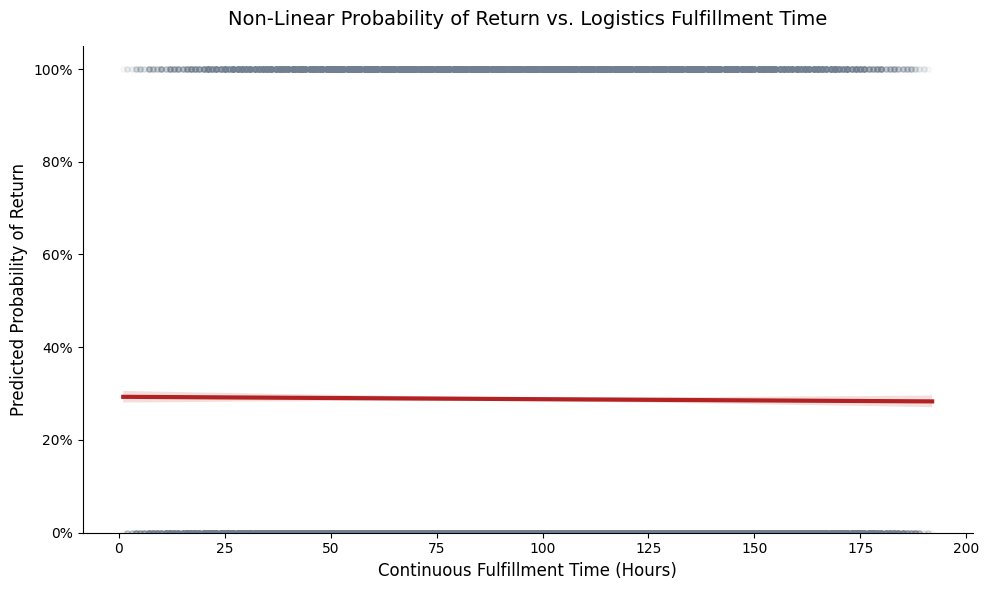

In [24]:
vis.plot_logistic_return_probability(df_logistics)

**What the chart shows:** A logistic regression of the return flag on fulfilment time (the only predictor), with a bootstrapped 95% band. The fitted curve is almost flat: about 29% at short fulfilment times, drifting down to about 28% at around 190 hours.

**Interpretation:** This agrees with the binned comparison in section 1: in this dataset, fulfilment time carries little information about whether an order is returned. If anything, the curve tilts very slightly downward (about one percentage point across the observed range), which is the opposite of the original hypothesis; no significance test was run and the change is small. A single logistic curve has a smooth, one-directional shape, so the binned comparison is the better check for a threshold effect (for example, a jump after 72 hours). The same limitations apply: one predictor, no adjustment for other factors, synthetic data.

### 3. Impulse Penalty: return rate by session intent

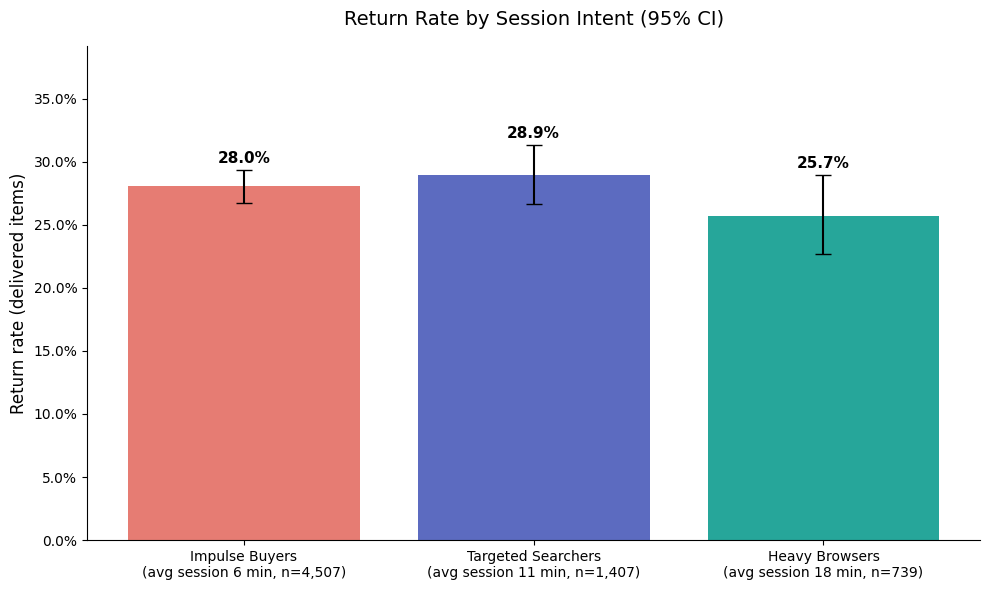

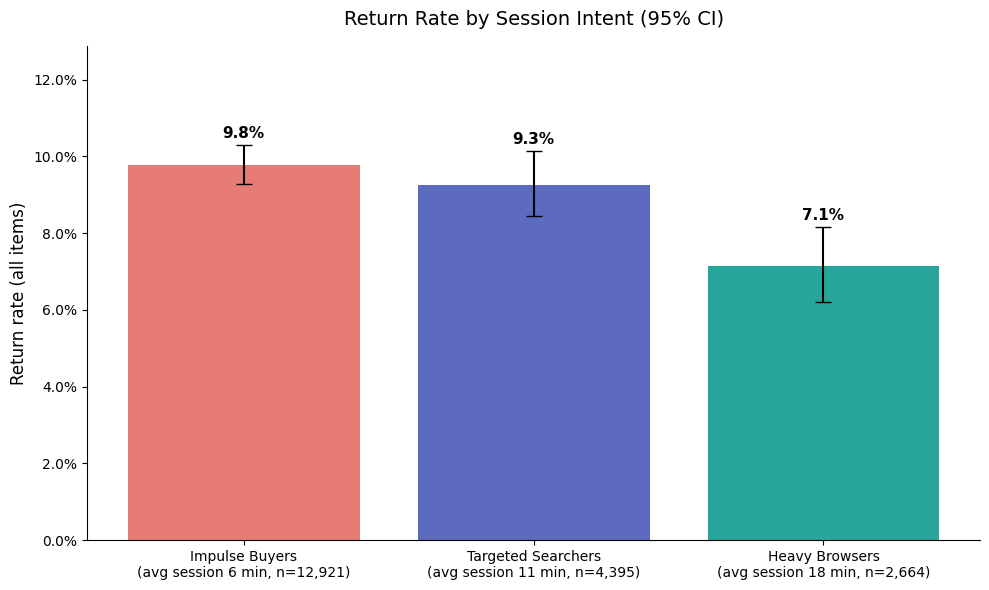

In [20]:
vis.plot_impulse_penalty(df_intent)                                     # delivered items
vis.plot_impulse_penalty(df_intent, rate_col='return_rate_all_items')  # all items

Only 9.1% of purchase sessions (16,446 of 181,466) could be matched to an order, so this covers a small subset. Among matched items, return rates are 9.8% (Impulse Buyers), 9.3% (Targeted Searchers) and 7.1% (Heavy Browsers) when all items are counted. Among delivered items, the only ones that can be returned, the rates are 28.0%, 28.9% and 25.7% (n = 4,507 / 1,407 / 739), and the approximate 95% intervals overlap. The lower all-items rate for Heavy Browsers is mostly explained by a smaller share of delivered items (28% vs 35%), not by a clear difference in return behaviour. This is an observational comparison with no adjustment for product mix, and it does not show that browsing reduces returns.